# Outbox y recibos semánticos: efecto confirmado, ACK perdido

## Objetivo
Distinguir tres problemas: entrega repetida, conflicto de intención y agotamiento de reintentos. El efecto del proveedor y el ACK del emisor están en dos SQLite independientes: nunca existe atomicidad compartida. El aporte es una auditoría pequeña ejecutable de un patrón conocido, no una garantía general de exactamente-una-vez.

## Métodos y supuestos
Emisor confirma job+outbox local; relay llama proveedor; proveedor confirma efecto+recibo local; luego emisor ACK. Inyectamos pérdida de respuesta sólo entre los dos últimos pasos. Ratios de fallos sintéticos Bernoulli independientes, ocho intentos máximos, claves estables y almacenamiento sin corrupción. Contrato proveedor fija política y conserva recibos indefinidamente durante el experimento.

Invariante bajo key_hash: para cada clave, a lo sumo un efecto persistente; cualquier payload distinto se rechaza. No deduce terminación: si se pierden las ocho respuestas, queda pendiente. Sin TTL/credenciales/red real.

Fuentes primarias: AWS Making retries safe with idempotent APIs, Richardson outbox/idempotent consumer, documentación SQLite. Cinco entradas verificadas en referencias.bib.

## Configuración y datos
Las tres políticas reciben la misma secuencia de pérdidas por semilla. Los probes de intención cambiada ocurren después de medir efectos y tiempo, por lo que no contaminan duplicados ni latencia principal.

In [1]:
import json
from pathlib import Path
from IPython.display import display, SVG
r=json.loads(Path("results/summary.json").read_text())
r["config"]

Out[0]: 
{'seeds': [0, 1, 2, 3, 4, 5, 6, 7],
 'sizes': [20, 100],
 'ack_loss_probabilities': [0, 0.35, 0.8],
 'attempt_budget': 8,
 'hypothesis': 'key_hash has zero duplicate effects, zero missing effects and rejects all changed-payload probes; no_dedup duplicates >0 under ACK loss; key_only accepts changed payload',
 'fault': 'after provider COMMIT and before sender ACK; independent Bernoulli per attempt',
 'dataset': 'synthetic positive integer effects, two independent SQLite files'}


## Resultados
Todas las cifras se leen del artefacto ejecutado. Tiempo es wall-clock local con fsync y trazado de memoria; no latencia de red ni capacidad de un proveedor comercial.

In [2]:
for row in r["summary"]:
    if row["n"]==100:
        print(row["ack_loss"],row["mode"], "duplicates=",row["mean_duplicates"],"completion=",row["mean_completion"],"conflict_rejection=",row["conflict_rejection_rate"],"seconds=",round(row["mean_seconds"],3))

0 no_dedup duplicates= 0 completion= 1.0 conflict_rejection= 0.0 seconds= 0.477
0 key_only duplicates= 0 completion= 1.0 conflict_rejection= 0.0 seconds= 0.425
0 key_hash duplicates= 0 completion= 1.0 conflict_rejection= 1.0 seconds= 0.388
0.35 no_dedup duplicates= 58.375 completion= 1.0 conflict_rejection= 0.0 seconds= 0.437
0.35 key_only duplicates= 0 completion= 1.0 conflict_rejection= 0.0 seconds= 0.369
0.35 key_hash duplicates= 0 completion= 1.0 conflict_rejection= 1.0 seconds= 0.429
0.8 no_dedup duplicates= 318.75 completion= 0.8362499999999999 conflict_rejection= 0.0 seconds= 0.835
0.8 key_only duplicates= 0 completion= 0.8362499999999999 conflict_rejection= 0.0 seconds= 0.497
0.8 key_hash duplicates= 0 completion= 0.8362499999999999 conflict_rejection= 1.0 seconds= 0.462


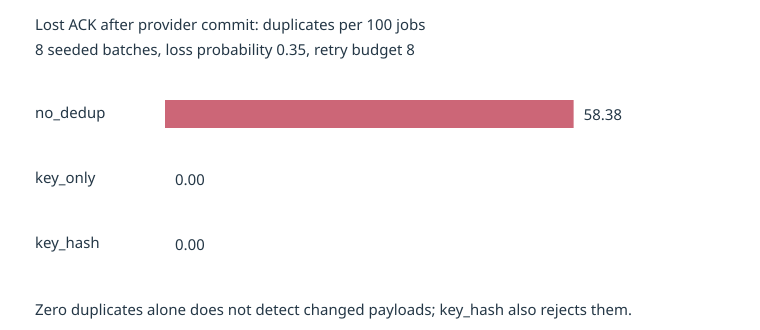

In [3]:
display(SVG(filename="results/duplicates.svg"))

### Interpretación
Cero duplicados con key_only no basta: acepta en silencio un payload divergente. key_hash rechaza conflicto, pero no puede convertir ocho respuestas perdidas en confirmación del emisor. Revisar completion junto con effects evita llamar pérdida de ACK a pérdida del efecto.

In [4]:
rows=r["summary"]
assert all(x["mean_duplicates"]==0 and x["mean_missing"]==0 and x["conflict_rejection_rate"]==1 for x in rows if x["mode"]=="key_hash")
assert all(x["conflict_rejection_rate"]==0 for x in rows if x["mode"]=="key_only")
assert all(x["mean_duplicates"]>0 for x in rows if x["mode"]=="no_dedup" and x["ack_loss"]>0)
print("Invariantes y controles negativos confirmados en el experimento sintético.")
r["environment"]

Invariantes y controles negativos confirmados en el experimento sintético.
Out[0]: 
{'python': '3.12.14',
 'sqlite': '3.53.1',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'processor': 'x86_64',
 'cpu_count': 9}


## Conclusiones y próxima prueba
El recibo debe acompañar al efecto en la transacción del proveedor. La outbox del emisor por sí sola no impide repetir efectos remotos. La huella detecta conflictos de intención pero no es autenticación. Próxima iteración: TTL de recibos y replay tardío, seguido por servidor/proceso remoto real y pruebas de corte en otras fronteras. Notebook ejecutado secuencialmente vía IPython in-process; no kernel Jupyter aislado.